#### Análise exploratória – 1. Visão geral e volume de trabalho

- Totais gerais: pontos, projetos, dias com coleta;
- Volume de pontos por mês;
- Distribuição por dia da semana e hora do dia;
- Tamanho e duração dos projetos.

Cada linha da coletora é classificada em:
- **Base**: estação de referência instalada no campo (`PointType = 6`);
- **Ponto digitado**: coordenada inserida/importada, sem medição GNSS (`Solution = 0`);
- **Ponto coletado**: ponto efetivamente medido com RTK.

In [4]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Garante a raiz do projeto como diretório de trabalho (Jupyter ou PyCharm)
raiz = Path.cwd()
if not (raiz / "dados").is_dir() and (raiz.parent / "dados").is_dir():
    os.chdir(raiz.parent)

ARQUIVO_LIMPO = "dados/dados_rtk_limpo.csv"
TIPO_BASE = 6        # PointType da estação base
SEM_SOLUCAO = 0      # Solution de quem não foi medido com GNSS

dados = pd.read_csv(ARQUIVO_LIMPO, encoding="utf-8-sig", low_memory=False)
dados["Time"] = pd.to_datetime(dados["Time"], errors="coerce")
dados["data"] = dados["Time"].dt.date

# Classificação de cada linha (a ordem importa: base primeiro)
dados["categoria"] = "Ponto coletado"
dados.loc[dados["Solution"] == SEM_SOLUCAO, "categoria"] = "Ponto digitado"
dados.loc[dados["PointType"] == TIPO_BASE, "categoria"] = "Base"

bases = dados[dados["categoria"] == "Base"]
digitados = dados[dados["categoria"] == "Ponto digitado"]
pontos = dados[dados["categoria"] == "Ponto coletado"].copy()   # usado no resto da análise

print(f"Base limpa: {len(dados)} linhas")

Base limpa: 46472 linhas


In [13]:
inicio, fim = pontos["Time"].min(), pontos["Time"].max()
dias_com_coleta = pontos["data"].nunique()
total = len(dados)

print(f"Período: {inicio:%d/%m/%Y} a {fim:%d/%m/%Y} ({(fim - inicio).days} dias corridos)")
print(f"Dias com coleta: {dias_com_coleta}")

print(f"\nTotal de linhas: {total}")
print(f"  Pontos coletados: {len(pontos):>6} ({len(pontos) / total:.1%})")
print(f"  Bases:            {len(bases):>6} ({len(bases) / total:.1%})")
print(f"  Pontos digitados: {len(digitados):>6} ({len(digitados) / total:.1%})")

print(f"\nProjetos (total): {dados['Projeto'].nunique()}")
print(f"  com pontos coletados: {pontos['Projeto'].nunique()}")
print(f"  com base registrada:  {bases['Projeto'].nunique()}")


Período: 23/04/2024 a 22/10/2026 (912 dias corridos)
Dias com coleta: 425

Total de linhas: 46472
  Pontos coletados:  45721 (98.4%)
  Bases:               559 (1.2%)
  Pontos digitados:    192 (0.4%)

Projetos (total): 523
  com pontos coletados: 484
  com base registrada:  516


            pontos  projetos  dias_campo
Time                                    
2024-04-01     151         6           4
2024-05-01     436         5           9
2024-06-01     574        10          10
2024-07-01     608        13          10
2024-08-01     905        14          17
2024-09-01    1171        10          11
2024-10-01    2196        14          13
2024-11-01    1361         9           8
2024-12-01    2918        13          11
2025-01-01    1514        23          18
2025-02-01       0         0           0
2025-03-01     491         5           6
2025-04-01    4879        27          19
2025-05-01     733        18          16
2025-06-01    2119        23          18
2025-07-01    3110        28          19
2025-08-01    1508        20          18
2025-09-01     988        21          19
2025-10-01    2704        33          23
2025-11-01    2066        31          17
2025-12-01     914        10          10
2026-01-01    2140        32          12
2026-02-01     4

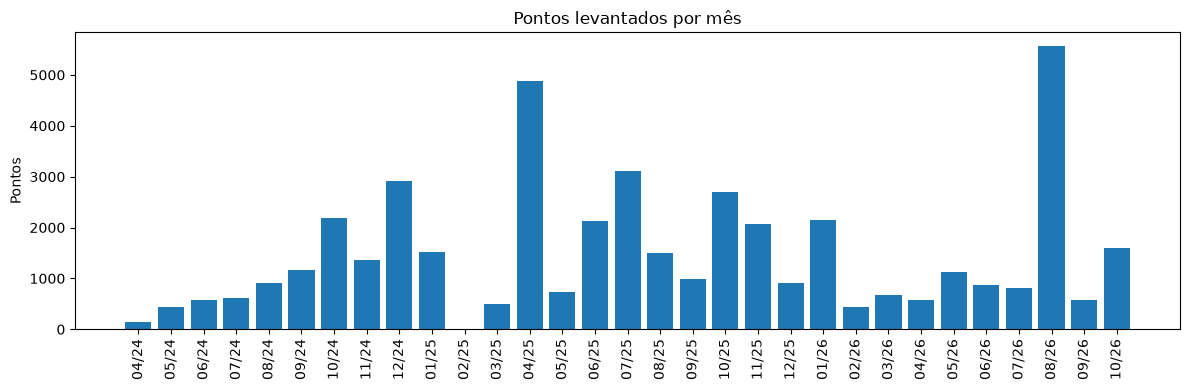

In [14]:
# asfreq("M") inclui os meses sem coleta com valor 0 (ex.: fev/2025)
por_mes = (pontos.set_index("Time").resample("MS").size()
           .rename("pontos").to_frame())
por_mes["projetos"] = pontos.set_index("Time").resample("MS")["Projeto"].nunique()
por_mes["dias_campo"] = pontos.set_index("Time").resample("MS")["data"].nunique()

print(por_mes.to_string())
print(f"\nMeses sem coleta: {[f'{m:%m/%Y}' for m in por_mes.index[por_mes['pontos'] == 0]]}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(por_mes.index.strftime("%m/%y"), por_mes["pontos"])
ax.set_title("Pontos levantados por mês")
ax.set_ylabel("Pontos")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

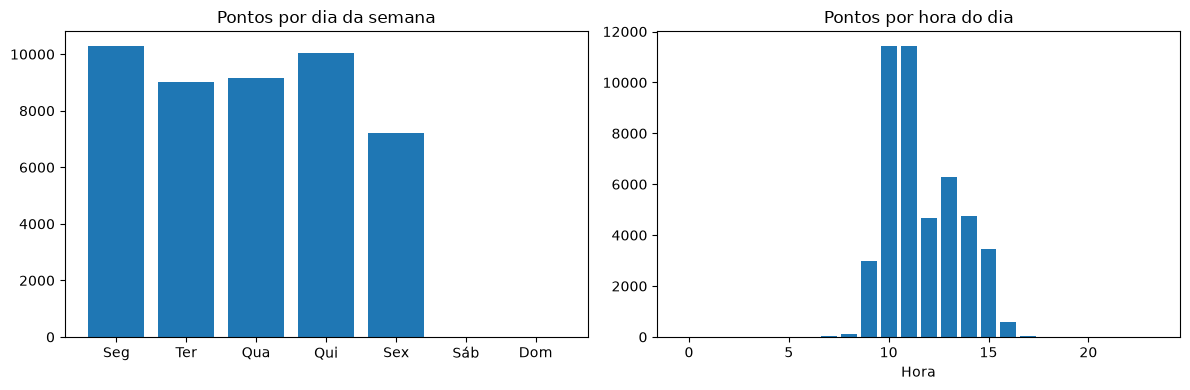

Coletas pela manhã (6h–11h59): 57% | tarde (12h–17h59): 43%


In [20]:
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

por_dia_semana = (pontos["Time"].dt.dayofweek.value_counts()
                  .reindex(range(7), fill_value=0))
por_hora = (pontos["Time"].dt.hour.value_counts()
            .reindex(range(24), fill_value=0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(DIAS, por_dia_semana.values)
ax1.set_title("Pontos por dia da semana")
ax2.bar(por_hora.index, por_hora.values)
ax2.set_title("Pontos por hora do dia")
ax2.set_xlabel("Hora")
plt.tight_layout()
plt.show()

manha = por_hora.loc[6:11].sum() / len(pontos)
print(f"Coletas pela manhã (6h–11h59): {manha:.0%} | tarde (12h–17h59): "
      f"{por_hora.loc[12:17].sum() / len(pontos):.0%}")